# CatDSGE for India: a 10% capital destruction

The model estimated in `03_catdsge_estimation.ipynb`, with capital destruction added back: how the impact on GDP varies across the posterior, the impulse responses, a counterfactual disaster in 2015Q1, and its welfare cost at first order. `05_catdsge_pf_disaster_example.ipynb` solves the same disaster in the nonlinear model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import xarray as xr

from matplotlib.colors import TwoSlopeNorm
from scipy.stats import gaussian_kde
from tqdm.auto import tqdm

import gEconpy as ge

from catdsge import (build_observed,
                     build_pymc_model,
                     build_welfare_model,
                     calibrate_india,
                     configure_session,
                     fixed_parameters,
                     load_estimation_statespace,
                     load_simulation_statespace,
                     median_and_hdi,
                     plot_clipped_densities,
                     plot_impact_heatmap,
                     plot_response_grid,
                     plot_shock_responses,
                     simulation_trace,
                     statespace_trace,
                     to_display_units)
from climate_risk.dsge.model_files import GCN_DIR
from climate_risk.plotting import PALETTE

configure_session()
data_dir = Path("data")

In [2]:
model = ge.model_from_gcn(GCN_DIR / "catdsge_v4.gcn")
panel = pd.read_parquet(data_dir / "india_mixed_frequency.parquet")
panel.index = panel.index.to_period("Q")

india_parameters = calibrate_india(model, panel)
india_model_parameters = model.parameters(**india_parameters)
india_steady_state = model.steady_state(verbose=False,
                                        progressbar=False,
                                        **india_parameters)

In [3]:
statespace = load_estimation_statespace()
estimated_shocks = list(statespace.shock_names)

observed = build_observed(panel)
fit_data = observed.set_axis(observed.index.to_timestamp())
pymc_model = build_pymc_model(statespace=statespace,
                              fit_data=fit_data,
                              model_parameters=india_model_parameters)

In [4]:
with xr.open_datatree(data_dir / "catdsge_flow_tight_shocks_idata.nc") as saved_trace:
    map_init_idata = saved_trace.load()
posterior_draws = map_init_idata.posterior.to_dataset()
solved = posterior_draws["deterministic_norm"] <= 1e-6

observed_data = xr.Dataset({"obs": (("time", "observed_state"), fit_data.to_numpy())},
                           coords={"time": fit_data.index.rename("time"),
                                   "observed_state": fit_data.columns})
statespace_idata = statespace_trace(draws=posterior_draws,
                                    parameter_values=fixed_parameters(statespace, india_model_parameters),
                                    observed_data=observed_data,
                                    group="posterior")

## 1. Simulation model

The simulation model is the estimation model plus the capital destruction block. Its shock covariance is the estimated one, with the disaster added as an uncorrelated shock whose standard deviation is the 10% destruction of `02_catdsge_prior_analysis.ipynb`.

In [5]:
simulation_statespace = load_simulation_statespace()
analysis_idata = simulation_trace(simulation_statespace=simulation_statespace,
                                  estimated_shocks=estimated_shocks,
                                  draws=posterior_draws,
                                  model_parameters=india_model_parameters,
                                  observed_data=observed_data,
                                  group="posterior")

## 2. Capital destruction across the posterior

The impact response of GDP over habit and the utilization cost, with the other estimated parameters at their posterior means. Dashed contours enclose 50%, 80% and 95% of the posterior draws of $(\phi_H, \psi_z)$.

In [6]:
POSTERIOR_MASS_LEVELS = [0.95, 0.8, 0.5]
DENSITY_GRID_POINTS = 200

posterior_habit_utilization = posterior_draws[["phi_H", "psi_z"]].to_dataframe()
posterior_kde = gaussian_kde(np.vstack([posterior_habit_utilization["phi_H"],
                                        np.log(posterior_habit_utilization["psi_z"])]))

density_phi_H, density_psi_z = np.meshgrid(np.linspace(0.0, 0.9, DENSITY_GRID_POINTS),
                                           np.geomspace(0.01, 10.0, DENSITY_GRID_POINTS))
posterior_density = posterior_kde(np.vstack([density_phi_H.ravel(), np.log(density_psi_z.ravel())]))
posterior_density = posterior_density.reshape(density_phi_H.shape)
density_at_draws = posterior_kde(posterior_kde.dataset)
density_levels = np.quantile(density_at_draws, q=[1 - mass for mass in POSTERIOR_MASS_LEVELS])


def add_posterior_contours(ax):
    posterior_contour = ax.contour(density_phi_H,
                                   density_psi_z,
                                   posterior_density,
                                   levels=density_levels,
                                   colors="k",
                                   linestyles="--",
                                   linewidths=1.0,
                                   zorder=5)
    mass_labels = [f"{mass:.0%}" for mass in POSTERIOR_MASS_LEVELS]
    ax.clabel(posterior_contour,
              fmt=dict(zip(posterior_contour.levels, mass_labels, strict=True)),
              fontsize=8)
    ax.plot([], [], color="k", ls="--", lw=1.0, label="posterior mass")

In [7]:
PHI_H_GRID = np.linspace(0.0, 0.9, 19)
PSI_Z_GRID = np.geomspace(0.01, 10.0, 19)


def impact_on_gdp(parameters):
    _, impact_matrix = model.solve_model(verbose=False,
                                         return_matrices=True,
                                         **parameters)
    return ge.matrix_to_dataframe(impact_matrix, model).loc["GDP", "epsilon_xi_K"] * -0.10


posterior_mean_parameters = {name: float(posterior_draws[name].mean())
                             for name in ["chi", "gamma_I", "theta_H", "gamma_H", "phi_pi", "phi_y", "rho_i",
                                          "phi_debt", "theta_w"]}
impact_gdp_posterior = xr.DataArray([[impact_on_gdp({**india_parameters,
                                                     **posterior_mean_parameters,
                                                     "phi_H": phi_H,
                                                     "psi_z": psi_z})
                                      for phi_H in PHI_H_GRID]
                                     for psi_z in tqdm(PSI_Z_GRID, desc="psi_z rows")],
                                    dims=["psi_z", "phi_H"],
                                    coords={"psi_z": PSI_Z_GRID, "phi_H": PHI_H_GRID})

psi_z rows:   0%|          | 0/19 [00:00<?, ?it/s]

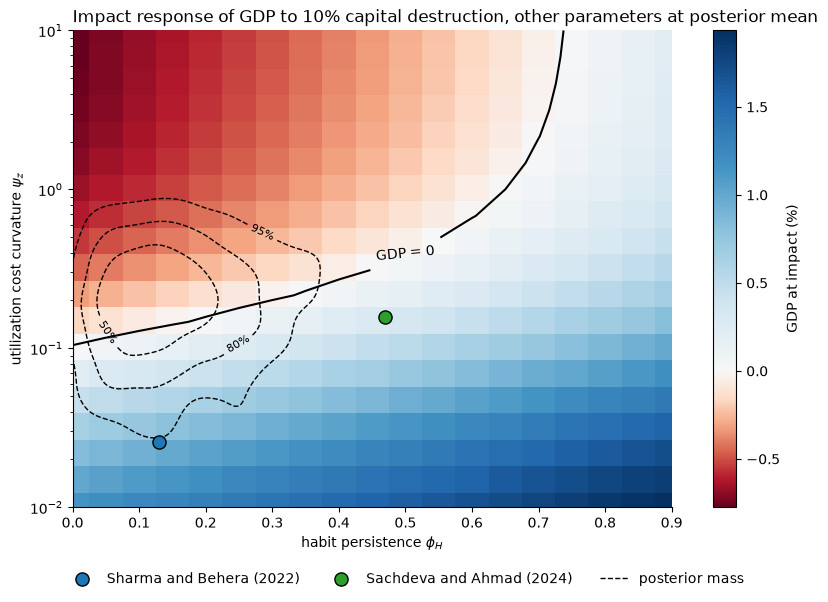

In [8]:
# Habit estimates of Sharma and Behera (2022) and Sachdeva and Ahmad (2024). The first report a''/a' directly, and the
# second report psi, with a''/a' = psi / (1 - psi).
literature_points = pd.DataFrame({"phi_H": [0.13, 0.47],
                                  "psi_z": np.array([0.58, 0.78 / (1 - 0.78)]) * india_model_parameters["psi_z_1"]},
                                 index=["Sharma and Behera (2022)", "Sachdeva and Ahmad (2024)"])

fig, ax = plt.subplots(figsize=(8, 5.5), layout="constrained")
mesh = plot_impact_heatmap(ax=ax,
                           impact=impact_gdp_posterior,
                           literature_points=literature_points,
                           xlabel=r"habit persistence $\phi_H$",
                           ylabel=r"utilization cost curvature $\psi_z$",
                           yscale="log",
                           norm=TwoSlopeNorm(vcenter=0.0))
add_posterior_contours(ax)
colorbar = fig.colorbar(mesh, ax=ax, label="GDP at impact (%)")
colorbar.ax.set_yscale("linear")
ax.set_title("Impact response of GDP to 10% capital destruction, other parameters at posterior mean", loc="left")
fig.legend(loc="lower center",
           bbox_to_anchor=(0.5, -0.08),
           ncol=3,
           frameon=False);

## 3. Posterior impulse responses

The grid applies each estimated shock alone at one posterior standard deviation. The estimated shocks are correlated, so they are orthogonalized by a Cholesky factorization of each draw's covariance, with the foreign block first: world shocks may move Indian shocks within the quarter, and Indian shocks may not move world ones. The second figure is the 10% capital destruction of `02_catdsge_prior_analysis.ipynb`, applied to the estimated model. Bands are 94% intervals over posterior draws.

In [9]:
IRF_QUARTERS = 40

posterior_irfs = simulation_statespace.impulse_response_function(analysis_idata,
                                                                 n_steps=IRF_QUARTERS,
                                                                 orthogonalize_shocks=True,
                                                                 shock_order=["epsilon_i_star",
                                                                              "epsilon_pi_star",
                                                                              "epsilon_Y_star",
                                                                              "epsilon_p_M_star",
                                                                              ...],
                                                                 random_seed=20261014)["irf"]

Sampling: []


Output()

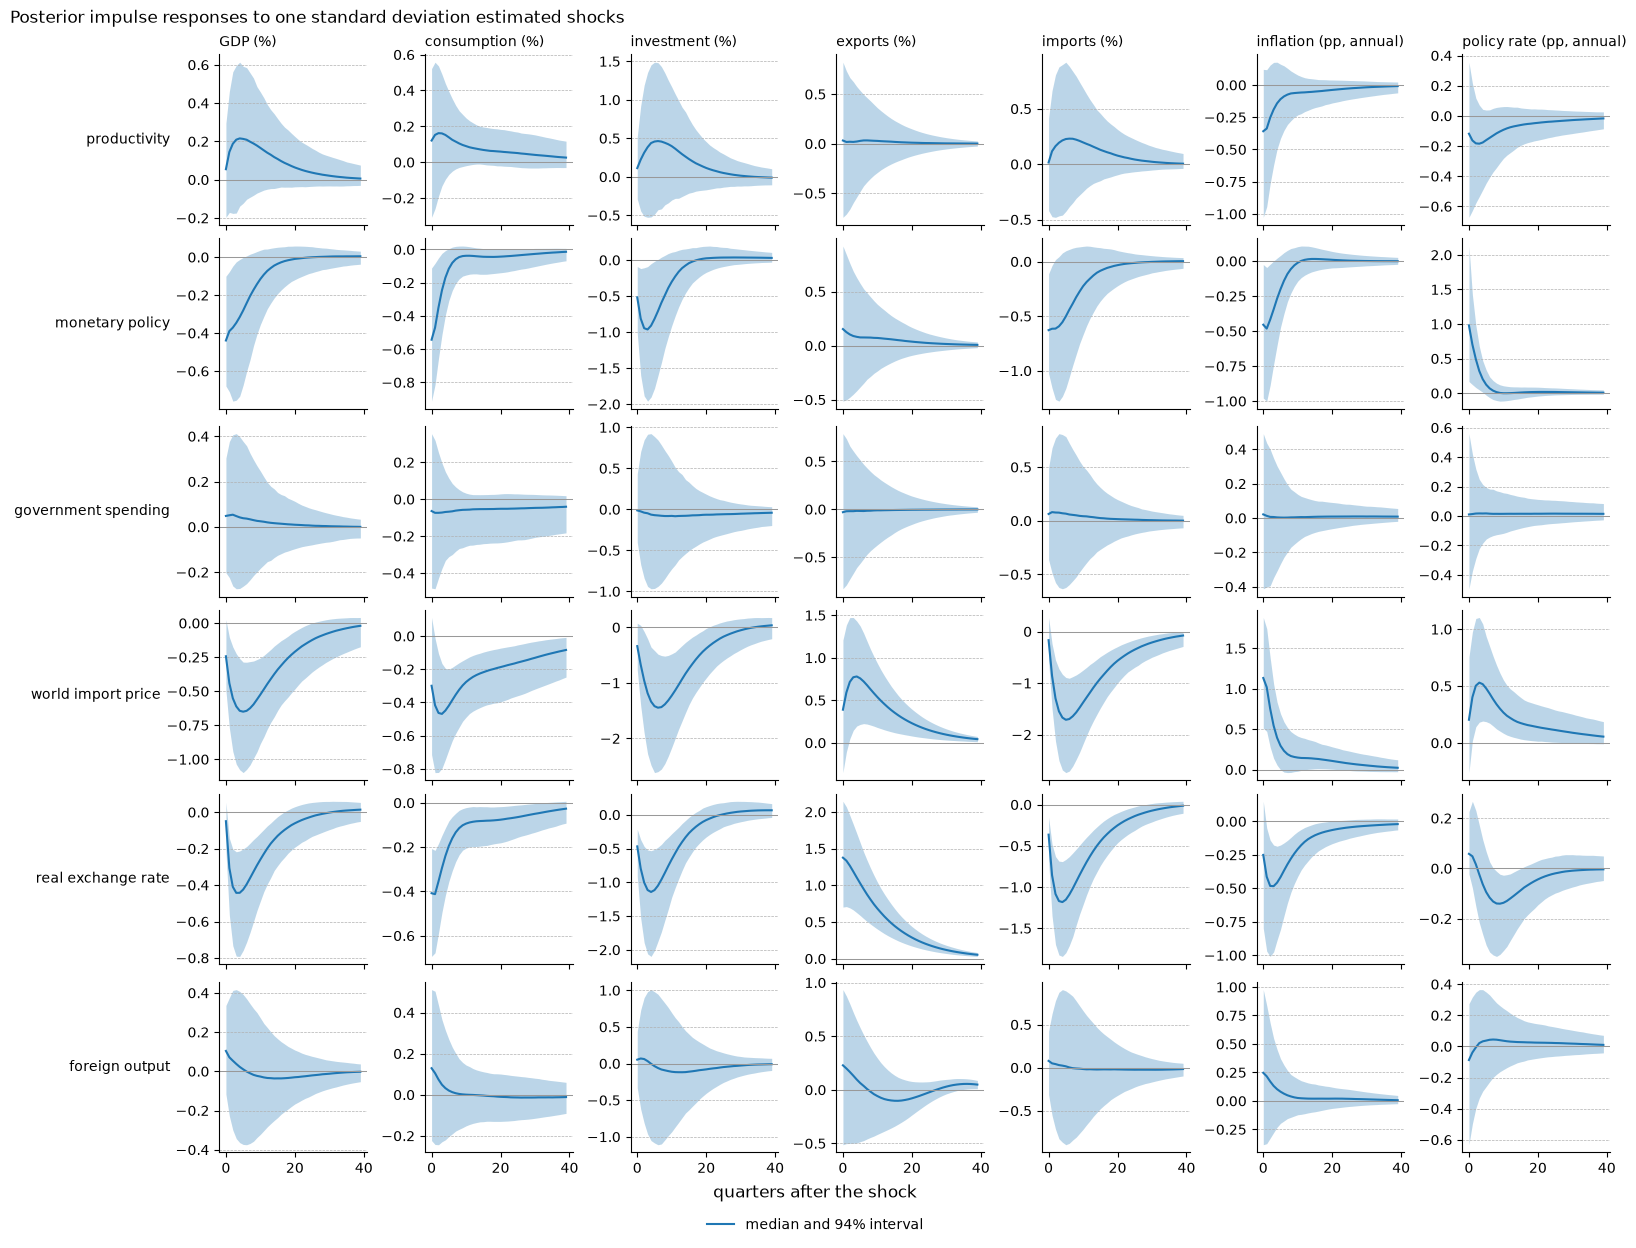

In [10]:
fig = plot_response_grid(irfs=posterior_irfs.rename(structural_shock="shock", state="variable"),
                         reference_irf=None,
                         shock_labels={"epsilon_A": "productivity",
                                       "epsilon_i": "monetary policy",
                                       "epsilon_G": "government spending",
                                       "epsilon_p_M_star": "world import price",
                                       "epsilon_q": "real exchange rate",
                                       "epsilon_Y_star": "foreign output"},
                         variables=["GDP", "C", "I", "X", "M", "pi", "i"],
                         policy_rate_ss=india_steady_state["i_ss"],
                         solved=solved)
fig.suptitle("Posterior impulse responses to one standard deviation estimated shocks", x=0.0, ha="left");

In [11]:
simulation_shocks = list(simulation_statespace.shock_names)
destruction_trajectory = np.zeros((IRF_QUARTERS, len(simulation_shocks)))
destruction_trajectory[0, simulation_shocks.index("epsilon_xi_K")] = -0.10
capital_destruction_irf = simulation_statespace.impulse_response_function(analysis_idata,
                                                                          shock_trajectory=destruction_trajectory,
                                                                          random_seed=20261014)["irf"]

Sampling: []


Output()

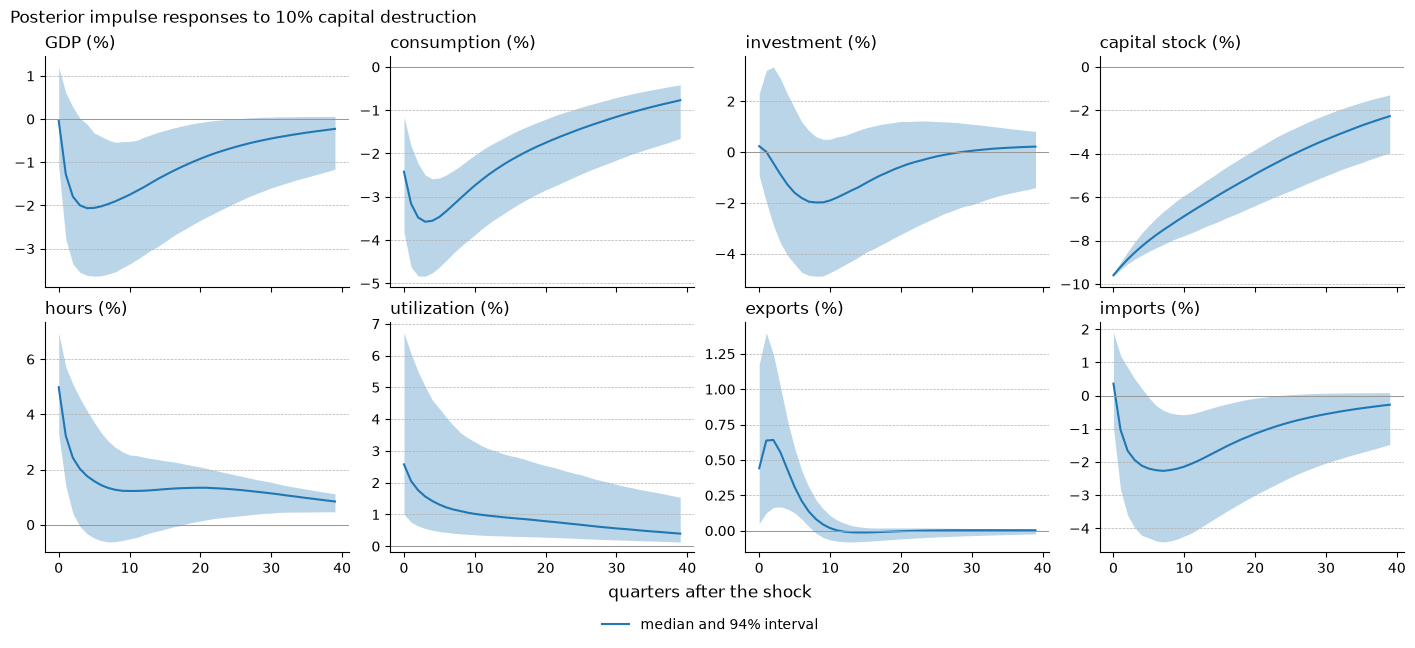

In [12]:
fig = plot_shock_responses(irf=capital_destruction_irf.rename(state="variable"),
                           reference_irf=None,
                           variables=["GDP", "C", "I", "K", "L", "z", "X", "M"],
                           policy_rate_ss=india_steady_state["i_ss"],
                           solved=solved)
fig.suptitle("Posterior impulse responses to 10% capital destruction", x=0.0, ha="left");

## 4. Counterfactual: 10% capital destruction in 2015Q1

The baseline is the economy as it stood in 2014Q4, left to evolve with no further shocks: for each posterior draw, the smoothed state at 2014Q4 propagated forward through the transition matrix, then re-trended with each series' mean growth. Real series and the debt ratio start from the data, and inflation is the model's own path around its steady state. The disaster's response sits on top of that baseline, so the band reflects parameter uncertainty alone. Levels are in trillion rupees per quarter at constant prices. Debt data are the IMF World Economic Outlook's fiscal-year series, held constant across the quarters of each fiscal year.

In [13]:
# The Kalman filter samplers read the data from constant_data.
filter_idata = xr.DataTree.from_dict({"posterior": statespace_idata["posterior"].to_dataset(),
                                      "observed_data": observed_data,
                                      "constant_data": xr.Dataset({"data": observed_data["obs"]})})
smoothed_states = statespace.sample_filter_outputs(filter_idata,
                                                   filter_output_names="smoothed_states",
                                                   random_seed=20261014)["posterior_predictive"]["smoothed_states"]
transition = statespace.sample_statespace_matrices(filter_idata,
                                                   matrix_names=["T"],
                                                   random_seed=20261014)["posterior_predictive"]["T"]

Sampling: []


Output()

Sampling: []


Output()

In [14]:
CRORE_PER_TRILLION_RUPEES = 1e5
SHOCK_QUARTER = pd.Period("2015Q1", freq="Q")
BASELINE_QUARTER = SHOCK_QUARTER - 1

fit_quarters = observed.index
data_dates = fit_quarters.to_timestamp()
outside_lockdown = observed["gdp_growth"].notna().to_numpy()
destruction_irf = capital_destruction_irf.rename(state="variable")

inflation_data = 400 * np.log(panel["cpi"]).diff().loc[fit_quarters]
# The panel places each fiscal year's debt on the first quarter of the next calendar year, and the WEO's fiscal year
# starts in April, so January to March belongs to the year before.
debt_by_quarter = panel["government_debt"].dropna()
debt_by_fiscal_year = pd.Series(debt_by_quarter.to_numpy(), index=debt_by_quarter.index.year - 1)
fiscal_years = [quarter.year if quarter.quarter >= 2 else quarter.year - 1 for quarter in fit_quarters]
debt_data = pd.Series(100 * debt_by_fiscal_year.reindex(fiscal_years).to_numpy(), index=fit_quarters)

In [15]:
state_path = [smoothed_states.sel(time=BASELINE_QUARTER.to_timestamp()).drop_vars("time")]
for _ in range(IRF_QUARTERS):
    state_path.append(xr.dot(transition, state_path[-1].rename(state="state_aux"), dim="state_aux"))
zero_shock_states = xr.concat(state_path, dim="time").where(solved)
state_change = zero_shock_states - zero_shock_states.isel(time=0)

horizon = xr.DataArray(np.arange(IRF_QUARTERS + 1), dims=["time"])
irf_from_start = destruction_irf.drop_vars("time").pad(time=(1, 0), constant_values=0.0).where(solved)

zero_shock_panels = {}
for title, column, variable in [("GDP", "gdp", "GDP"),
                                ("Consumption", "consumption", "C"),
                                ("Investment", "investment", "I"),
                                ("Exports", "exports", "X"),
                                ("Imports", "imports", "M")]:
    data = panel[column].loc[fit_quarters] / CRORE_PER_TRILLION_RUPEES
    mean_growth = np.log(panel[column]).diff().loc[fit_quarters][outside_lockdown].mean()
    baseline = data.loc[BASELINE_QUARTER] * np.exp(mean_growth * horizon + state_change.sel(state=variable))
    zero_shock_panels[title] = {"unit": "trillion rupees per quarter",
                                "data": data,
                                "baseline": baseline,
                                "counterfactual": baseline * np.exp(irf_from_start.sel(variable=variable))}

inflation_baseline = 400 * (np.log(india_parameters["pi_bar"]) + zero_shock_states.sel(state="pi"))
zero_shock_panels["CPI inflation"] = {"unit": "% a year, annualized quarterly rate",
                                      "data": inflation_data,
                                      "baseline": inflation_baseline,
                                      "counterfactual": inflation_baseline
                                      + to_display_units(irf=irf_from_start,
                                                         variable="pi",
                                                         policy_rate_ss=india_steady_state["i_ss"])}

debt_baseline = debt_data.loc[BASELINE_QUARTER] * np.exp(state_change.sel(state="B")
                                                         - state_change.sel(state="GDP"))
zero_shock_panels["Government debt"] = {"unit": "% of annual GDP",
                                        "data": debt_data,
                                        "baseline": debt_baseline,
                                        "counterfactual": debt_baseline
                                        * np.exp(irf_from_start.sel(variable="B") - irf_from_start.sel(variable="GDP"))}

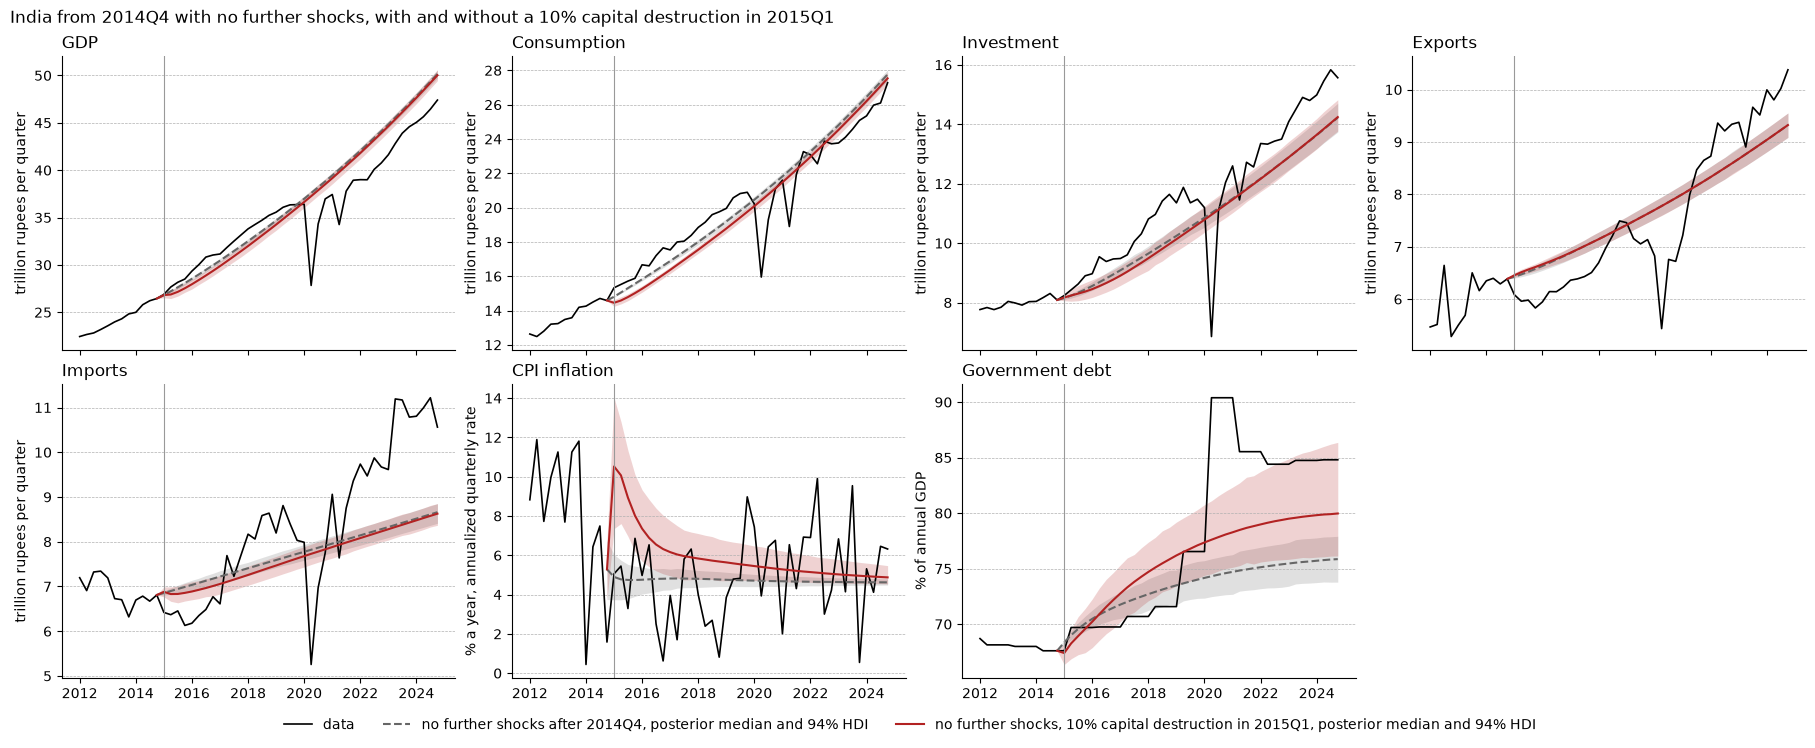

In [16]:
zero_shock_dates = pd.period_range(start=BASELINE_QUARTER, periods=IRF_QUARTERS + 1, freq="Q").to_timestamp()

fig, axes = plt.subplots(nrows=2,
                         ncols=4,
                         figsize=(18, 7),
                         sharex=True,
                         layout="constrained")
for ax, (title, series) in zip(axes.flat, zero_shock_panels.items()):
    ax.plot(data_dates,
            series["data"],
            color="k",
            lw=1.2,
            label="data")
    for path, color, linestyle, label in [(series["baseline"], "0.4", "--", "no further shocks after 2014Q4"),
                                          (series["counterfactual"],
                                           "firebrick",
                                           "-",
                                           "no further shocks, 10% capital destruction in 2015Q1")]:
        median, interval = median_and_hdi(path)
        ax.fill_between(zero_shock_dates,
                        interval.sel(ci_bound="lower"),
                        interval.sel(ci_bound="upper"),
                        color=color,
                        alpha=0.2,
                        linewidth=0)
        ax.plot(zero_shock_dates,
                median,
                color=color,
                ls=linestyle,
                lw=1.5,
                label=f"{label}, posterior median and 94% HDI")
    ax.axvline(SHOCK_QUARTER.to_timestamp(), color="0.6", lw=0.8)
    ax.set_title(title, loc="left")
    ax.set_ylabel(series["unit"])
axes.flat[-1].set_axis_off()

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles=handles,
           labels=labels,
           loc="upper center",
           bbox_to_anchor=(0.5, 0.0),
           ncol=len(labels),
           frameon=False)
fig.suptitle("India from 2014Q4 with no further shocks, with and without a 10% capital destruction in 2015Q1",
             x=0.0,
             ha="left");

Losses are the counterfactual minus the baseline, summed per posterior draw over each window, in trillion rupees and as a share of the variable's annual total in the year before the shock.

In [17]:
base_year = SHOCK_QUARTER.year - 1
last_year = (SHOCK_QUARTER + IRF_QUARTERS - 1).year
loss_windows = {f"{SHOCK_QUARTER.year} (shock year)": slice(0, 4),
                f"{SHOCK_QUARTER.year + 1} to {last_year}": slice(4, None),
                f"{SHOCK_QUARTER.year} to {last_year}": slice(None)}

zero_shock_impact_rows = {}
for title in ["GDP", "Consumption", "Investment", "Exports", "Imports"]:
    series = zero_shock_panels[title]
    loss = (series["counterfactual"] - series["baseline"]).isel(time=slice(1, None))
    base_year_total = series["data"][series["data"].index.year == base_year].sum()

    for window, quarters in loss_windows.items():
        window_loss = loss.isel(time=quarters).sum("time", skipna=False)
        zero_shock_impact_rows[(title, window)] = {
            ("trillion rupees", "mean"): float(window_loss.mean()),
            ("trillion rupees", "5%"): float(window_loss.quantile(0.05)),
            ("trillion rupees", "95%"): float(window_loss.quantile(0.95)),
            (f"% of {base_year} annual", "mean"): float(100 * window_loss.mean() / base_year_total),
            (f"% of {base_year} annual", "5%"): float(100 * window_loss.quantile(0.05) / base_year_total),
            (f"% of {base_year} annual", "95%"): float(100 * window_loss.quantile(0.95) / base_year_total)}

zero_shock_impact_table = pd.DataFrame.from_dict(zero_shock_impact_rows, orient="index")
zero_shock_impact_table.columns = pd.MultiIndex.from_tuples(zero_shock_impact_table.columns)
zero_shock_impact_table.style.format("{:.2f}")

## 5. Welfare cost of the 2015 disaster

The welfare cost is the consumption-equivalent variation $\lambda$, the permanent percentage change in consumption that changes lifetime utility $U_t = u_t + \beta_t \mathbb{E}_t U_{t+1}$ by as much as the disaster does. Period utility is the model's own,

$$u_t = \frac{(C_t - \phi_H C_{t-1})^{1 - \sigma}}{1 - \sigma} - \Theta \, \nu_{w,t} \frac{L_t^{1 + \chi}}{1 + \chi}$$

To first order the disaster moves lifetime utility by the discounted sum of its effect on each quarter's utility, and scaling consumption by $1 + \lambda$ moves it by $\lambda (C (1 - \phi_H))^{1 - \sigma} / (1 - \beta)$:

$$\begin{aligned}
\Delta U &= (C (1 - \phi_H))^{-\sigma} (1 - \beta \phi_H) \, C \sum_{t \geq 1} \beta^{t-1} \hat{C}_t - \Theta \, \nu_w L^{1 + \chi} \sum_{t \geq 1} \beta^{t-1} \left(\hat{L}_t + \frac{\hat{\nu}_{w,t}}{1 + \chi}\right) \\
\lambda &= \frac{(1 - \beta) \, \Delta U}{(C (1 - \phi_H))^{1 - \sigma}}
\end{aligned}$$

Hats are the disaster's log deviations, and the discounted sums are $(I - \beta T)^{-1} R \, \varepsilon_{\xi_K}$ in the simulation statespace. The steady state and both matrices are the statespace's symbolic graphs, so the cost is a deterministic of the estimation model and is evaluated over the posterior with `pm.compute_deterministics`. At first order the cost does not depend on the state the economy is in when the disaster arrives, so it is the same from 2014Q4 as from the steady state.

The figure prices the cost as the one-off consumption transfer in 2015Q1 that leaves the household as well off as without the disaster, $\Delta U$ divided by the marginal utility of 2015Q1 consumption $(C (1 - \phi_H))^{-\sigma} (1 - \beta \phi_H)$. The transfer is in quarters of steady-state consumption, converted to rupees at 2014Q4 consumption. Its consumption and hours components add up to the total.

In [18]:
WELFARE_COMPONENTS = {"": "total",
                      "_consumption": "consumption",
                      "_hours": "hours and wage dispersion"}

welfare_model = build_welfare_model(pymc_model, simulation_statespace)
welfare_measures = [f"{measure}{suffix}"
                    for measure in ["welfare_cost", "compensating_transfer"]
                    for suffix in WELFARE_COMPONENTS]
welfare_costs = pm.compute_deterministics(posterior_draws,
                                          model=welfare_model,
                                          var_names=welfare_measures).where(solved)

Output()

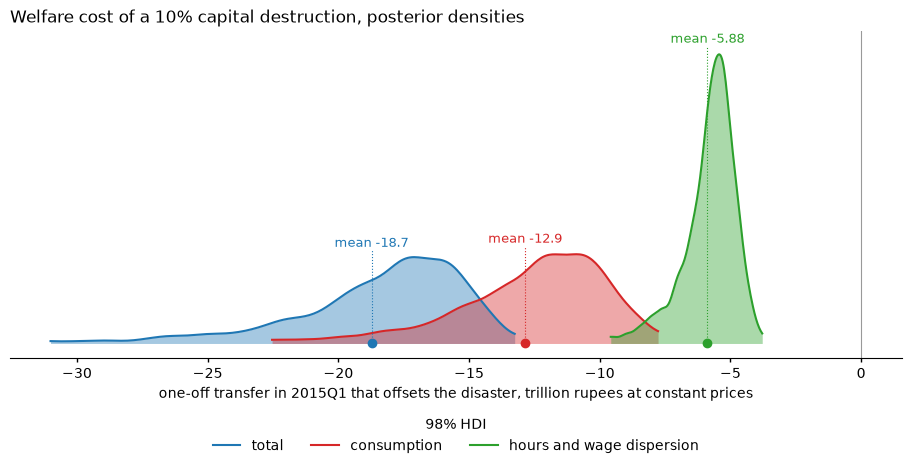

In [19]:
baseline_quarterly_consumption = zero_shock_panels["Consumption"]["data"].loc[BASELINE_QUARTER]
transfers = xr.Dataset({label: baseline_quarterly_consumption * welfare_costs[f"compensating_transfer{suffix}"]
                        for suffix, label in WELFARE_COMPONENTS.items()})
transfer_samples = transfers.stack(sample=("chain", "draw")).dropna("sample").drop_vars(["sample", "chain", "draw"])

plot_clipped_densities(samples=transfer_samples,
                       colors=[PALETTE["primary"], PALETTE["secondary"], "tab:green"],
                       xlabel=f"one-off transfer in {SHOCK_QUARTER} that offsets the disaster, trillion rupees at "
                              "constant prices",
                       title="Welfare cost of a 10% capital destruction, posterior densities");